# CLAP: connecting sounds and text

**CLAP** (Contrastive Language-Audio Pretraining) is to audio what CLIP (module 4) is to images. It has two encoders:

- an **audio encoder** that turns a 10 s recording into a vector of 512 numbers. Its input is a log-mel spectrogram
  (see the `Spectrogram` notebook), and it is a transformer over patches of the spectrogram (HTS-AT,
  [Chen et al. 2022](https://arxiv.org/abs/2202.00874));
- a **text encoder** (RoBERTa) that turns a description such as *"a dog barking in the distance"* into a vector of
  512 numbers as well.

They are trained together on millions of (recording, caption) pairs with a **contrastive loss**: the vectors of a
recording and of its caption are pulled together, and the vectors of non-matching pairs are pushed apart. After
training, a recording and a description of it are close in the shared 512-dimensional space.

That makes CLAP useful without any training of our own:

- **zero-shot classification**: write a description of every class, and pick the class whose description is
  closest to the recording;
- **search**: find the recordings closest to a text query;
- **features**: the audio vectors are good inputs for a small classifier trained on a few labels.

We use [`laion/larger_clap_general`](https://huggingface.co/laion/larger_clap_general) from LAION
([Wu et al. 2023](https://arxiv.org/abs/2211.06687)), trained on general sounds, music and speech, and try it on the
**BSD10k** dataset of Freesound clips.

In [1]:
import wave
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import s3fs
import torch
import torch.nn.functional as F
import torchaudio
from IPython.display import Audio, display
from transformers import ClapModel, ClapProcessor
from transformers.utils import logging as transformers_logging

transformers_logging.set_verbosity_error()  # hide the report of unused pre-training weights
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

MODEL = 'laion/larger_clap_general'
processor = ClapProcessor.from_pretrained(MODEL)
model = ClapModel.from_pretrained(MODEL).to(device).eval()

print(f'audio encoder: {sum(p.numel() for p in model.audio_model.parameters()) / 1e6:.0f}M parameters, '
      f'text encoder: {sum(p.numel() for p in model.text_model.parameters()) / 1e6:.0f}M parameters, '
      f'shared space: {model.config.projection_dim} dimensions')

device: cuda


audio encoder: 68M parameters, text encoder: 125M parameters, shared space: 512 dimensions


## The dataset: BSD10k

[BSD10k](https://zenodo.org/records/19868804) (Music Technology Group, Universitat Pompeu Fabra; CC BY 4.0) has
10,956 Freesound clips (up to 30 s, 44.1 kHz mono), each labeled by annotators with one of 23 classes of the
**Broad Sound Taxonomy**, and a confidence from 1 to 5. The classes are grouped into 5 top-level classes: music,
instrument samples, speech, sound effects and soundscapes.

In [2]:
BSD = 'danylo-ucla/bsd/bsd10k'
fs = s3fs.S3FileSystem()

metadata = pd.read_csv(f's3://{BSD}/metadata/BSD10k_metadata.csv')
taxonomy = pd.read_csv(f's3://{BSD}/metadata/BST_description.csv').set_index('class_key')
classes = taxonomy[taxonomy.second_level.notna() & (taxonomy.second_level != 'Other')]

print(len(metadata), 'clips')
display(metadata.head(3))
classes[['top_level', 'second_level', 'examples']].assign(clips=metadata['class'].value_counts())

10956 clips


,sound_id,class,class_idx,class_top,confidence,uploader,license,title,tags,description
0,185755,fx-o,401,fx,4,marcgp13,http://creativecommons.org/licenses/by/3.0/,microwave_oven.wav,"campus-upf,UPF-CS13,microwave,heat,bell,noise","A microwave oven operating, including the soun..."
1,358405,is-w,203,is,5,MTG,http://creativecommons.org/licenses/by/3.0/,Sax Alto - F5,"good-sounds,single-note,multisample,sax,neuman...",Recorded in the context of the good-sounds.org...
2,358760,is-w,203,is,4,MTG,http://creativecommons.org/licenses/by/3.0/,Sax Alto - G# Major,"good-sounds,sax,neumann-U87,GsharpMajor,scale,...",Recorded in the context of the good-sounds.org...


,top_level,second_level,examples,clips
class_key,,,,
m-sp,Music,Solo percussion,"rhythmic patterns, unpitched percussion excerp...",683
m-si,Music,Solo instrument,"isolated melody or sequence of notes, solo sin...",721
m-m,Music,Multiple instruments,"orchestra, band, duet, multi-instrument compos...",323
is-p,Instrument samples,Percussion,"drum, snare, gong, bell, xylophone",606
is-s,Instrument samples,String,"guitar, violin, harp, mandolin",528
is-w,Instrument samples,Wind,"woodwind, brass, flute, trumpet, saxophone",566
is-k,Instrument samples,Piano / Keyboard instruments,"piano, harspichord, organ",362
is-e,Instrument samples,Synths / Electronic,"synthesizers (analog/digital), synthesized or ...",297
sp-s,Speech,Solo speech,"talking, script reading",806


The audio files are WAVs in S3, `s3://danylo-ucla/bsd/bsd10k/audio/<sound_id>.wav`. CLAP looks at 10 s of audio
sampled at 48 kHz, so we read only the first 10 s of each file and resample them from 44.1 kHz.

In [3]:
CLAP_RATE = 48000


def load_clip(sound_id, seconds=10):
    # Python's wave module reads the header, then only the samples we ask for.
    with fs.open(f'{BSD}/audio/{sound_id}.wav', 'rb') as f, wave.open(f) as w:
        rate = w.getframerate()
        samples = np.frombuffer(w.readframes(seconds * rate), dtype=np.int16) / 32768  # 16-bit -> [-1, 1]
    return torchaudio.functional.resample(torch.tensor(samples, dtype=torch.float32), rate, CLAP_RATE).numpy()


def load_clips(sound_ids):
    with ThreadPoolExecutor(16) as pool:  # downloads in parallel
        return list(pool.map(load_clip, sound_ids))

## A few examples

In [4]:
examples = metadata.set_index('sound_id').loc[
    [264611, 42917, 25907, 244054, 148547, 354592, 239077, 325255]].reset_index()
example_waves = load_clips(examples.sound_id)

for (_, clip), wave_48k in zip(examples.iterrows(), example_waves):
    print(f"{clip['class']} ({taxonomy.second_level[clip['class']]}): '{clip.title}' by {clip.uploader}, "
          f"{clip.license}, https://freesound.org/s/{clip.sound_id}/")
    # Played back at 16 kHz to keep this notebook small: the model gets the 48 kHz version.
    display(Audio(torchaudio.functional.resample(torch.tensor(wave_48k), CLAP_RATE, 16000).numpy(), rate=16000))

sp-s (Solo speech): 'there's nothing on tv.wav' by shadoWisp, http://creativecommons.org/licenses/by/3.0/, https://freesound.org/s/264611/


fx-a (Animals): 'Owl.WAV' by inchadney, https://creativecommons.org/licenses/by/4.0/, https://freesound.org/s/42917/


fx-v (Vehicles): 'Cars Passing.wav' by Percy Duke, http://creativecommons.org/licenses/by/3.0/, https://freesound.org/s/25907/


ss-n (Nature): 'Thunder002.ogg' by lennyboy, http://creativecommons.org/publicdomain/zero/1.0/, https://freesound.org/s/244054/


is-k (Piano / Keyboard instruments): 'PIANO_MED_G3.wav' by neatonk, http://creativecommons.org/licenses/by/3.0/, https://freesound.org/s/148547/


is-w (Wind): 'Flute - C5' by MTG, http://creativecommons.org/licenses/by/3.0/, https://freesound.org/s/354592/


m-sp (Solo percussion): 'Drumloop Jungle or not to jungle - 2 bar - 100 BPM (swing).WAV' by Bronxio, http://creativecommons.org/publicdomain/zero/1.0/, https://freesound.org/s/239077/


fx-o (Objects / House appliances): 'Ding 1' by deleted_user_2104797, http://creativecommons.org/publicdomain/zero/1.0/, https://freesound.org/s/325255/


## What the audio encoder sees

The processor turns each waveform into a log-mel spectrogram, as in the `Spectrogram` notebook, with its own
parameters: 64 mel bands from 50 Hz to 14 kHz, windows of 1024 samples (21 ms) every 480 samples (10 ms), so
1001 frames for 10 s.

{'sampling_rate': 48000, 'fft_window_size': 1024, 'hop_length': 480, 'feature_size': 64, 'frequency_min': 50, 'frequency_max': 14000, 'max_length_s': 10, 'padding': 'repeatpad', 'truncation': 'rand_trunc'}


{'input_features': (8, 1, 1001, 64), 'is_longer': (8, 1)}


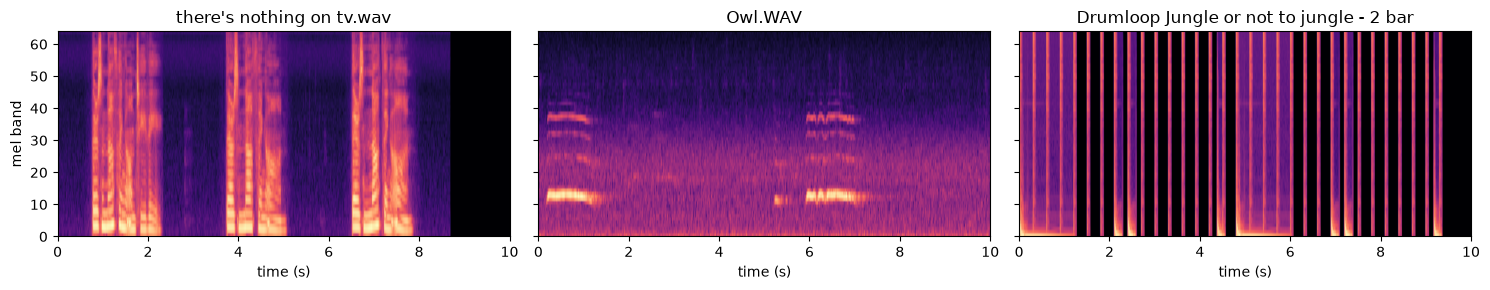

In [5]:
fe = processor.feature_extractor
print({k: getattr(fe, k) for k in ['sampling_rate', 'fft_window_size', 'hop_length', 'feature_size',
                                   'frequency_min', 'frequency_max', 'max_length_s', 'padding', 'truncation']})

inputs = processor(audio=example_waves, sampling_rate=CLAP_RATE, return_tensors='pt')
print({k: tuple(v.shape) for k, v in inputs.items()})  # input_features: [clips, 1, frames, mel bands]

fig, axes = plt.subplots(1, 3, figsize=(15, 3), sharey=True)
for ax, i in zip(axes, [0, 1, 6]):
    ax.imshow(inputs['input_features'][i, 0].T, origin='lower', aspect='auto', cmap='magma', extent=[0, 10, 0, 64])
    ax.set(title=examples.title[i][:40], xlabel='time (s)')
axes[0].set_ylabel('mel band')
plt.tight_layout()
plt.show()

The 8.7 s of speech (left) are followed by silence; the 4.8 s drum loop (right) is played twice, then silence.

## Audio and text embeddings

`get_audio_features` and `get_text_features` run the two encoders and project their outputs into the shared space
(`pooler_output`). We normalize the vectors to length 1, so that the dot product of two vectors is their **cosine
similarity**: 1 for the same direction, 0 for unrelated.

In [6]:
@torch.no_grad()
def embed_audio(waves, batch_size=32):
    embeddings = []
    for i in range(0, len(waves), batch_size):
        inputs = processor(audio=waves[i: i + batch_size], sampling_rate=CLAP_RATE, return_tensors='pt').to(device)
        embeddings.append(model.get_audio_features(**inputs).pooler_output)
    return F.normalize(torch.cat(embeddings), dim=-1).cpu()  # [clips, 512]


@torch.no_grad()
def embed_text(texts):
    inputs = processor(text=texts, return_tensors='pt', padding=True).to(device)
    return F.normalize(model.get_text_features(**inputs).pooler_output, dim=-1).cpu()  # [texts, 512]


example_audio = embed_audio(example_waves)
captions = ['a woman talking', 'an owl hooting', 'cars passing by', 'a thunderstorm',
            'a piano note', 'a flute playing one note', 'a drum loop', 'a glass clinking']
caption_text = embed_text(captions)
print('audio:', tuple(example_audio.shape), 'text:', tuple(caption_text.shape))

audio: (8, 512) text: (8, 512)


The cosine similarity of every clip with every caption. During training, CLAP turned similarities into
probabilities with a softmax over the captions, after multiplying them by a learned temperature
(`logit_scale_a`, about 39): we do the same. Each row then sums to 1.

In [7]:
logit_scale = model.logit_scale_a.exp().item()
print(f'temperature: {logit_scale:.1f}')


def show_scores(similarity, rows, columns):
    probabilities = (similarity * logit_scale).softmax(dim=-1).numpy()
    display(pd.DataFrame(probabilities, index=rows, columns=columns).style
            .background_gradient(cmap='Greens', axis=None).format(precision=2))


similarity = example_audio @ caption_text.T  # [clips, captions]
show_scores(similarity, examples.title.str[:40], captions)

temperature: 38.7


,a woman talking,an owl hooting,cars passing by,a thunderstorm,a piano note,a flute playing one note,a drum loop,a glass clinking
title,,,,,,,,
there's nothing on tv.wav,0.84,0.00,0.00,0.00,0.15,0.00,0.00,0.00
Owl.WAV,0.00,0.99,0.00,0.00,0.00,0.00,0.00,0.00
Cars Passing.wav,0.00,0.00,0.98,0.02,0.00,0.00,0.00,0.00
Thunder002.ogg,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
PIANO_MED_G3.wav,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
Flute - C5,0.00,0.00,0.01,0.00,0.00,0.99,0.00,0.00
Drumloop Jungle or not to jungle - 2 bar,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
Ding 1,0.00,0.00,0.00,0.00,0.02,0.00,0.00,0.98


Every clip is matched to its own caption, with captions we wrote ourselves and no training.

## Zero-shot classification

Now the classes of the dataset. We take a random sample of 30 clips from each top-level class, among the clips
whose annotators were confident (4 or 5). A clip is classified by comparing its embedding with the embedding of a
text **prompt** for each class.

In [8]:
TOP_LEVEL = {'m': 'Music', 'is': 'Instrument samples', 'sp': 'Speech', 'fx': 'Sound effects', 'ss': 'Soundscapes'}

sample = (metadata[metadata.confidence >= 4]
          .groupby('class_top', group_keys=False).sample(30, random_state=434)
          .reset_index(drop=True))
print(sample.class_top.map(TOP_LEVEL).value_counts().to_dict())

sample_waves = load_clips(sample.sound_id)  # 150 clips: a minute or two
sample_audio = embed_audio(sample_waves)
sample_audio.shape

{'Sound effects': 30, 'Instrument samples': 30, 'Music': 30, 'Speech': 30, 'Soundscapes': 30}


torch.Size([150, 512])

In [9]:
def zero_shot(prompts):
    # prompts: one text per top-level class, in the order of TOP_LEVEL. Returns the predicted class keys.
    similarity = sample_audio @ embed_text(list(prompts)).T
    return np.array(list(TOP_LEVEL))[similarity.argmax(dim=1).numpy()]


prompt_sets = {
    'class names': ['music', 'instrument sample', 'speech', 'sound effect', 'soundscape'],
    '"the sound of ..."': ['the sound of music', 'the sound of a single note played on a musical instrument',
                           'the sound of a person speaking', 'a sound effect', 'the ambient sound of a place'],
    'descriptions': ['a piece of music: a melody, a song, a loop or a beat',
                     'a single note or a scale played on one musical instrument',
                     'a person speaking or people talking',
                     'a sound effect: an object, a machine, a vehicle, an animal or a human action',
                     'a soundscape: the background sound of a city, nature or a room'],
}
predictions = {name: zero_shot(prompts) for name, prompts in prompt_sets.items()}
pd.DataFrame({name: {TOP_LEVEL[k]: (p == sample.class_top)[sample.class_top == k].mean() for k in TOP_LEVEL}
              | {'all': (p == sample.class_top).mean()}
              for name, p in predictions.items()}).style.format('{:.0%}').set_caption('accuracy')

,class names,"""the sound of ...""",descriptions
Music,3%,53%,57%
Instrument samples,43%,70%,77%
Speech,63%,23%,13%
Sound effects,40%,63%,53%
Soundscapes,40%,17%,20%
all,38%,45%,44%


Chance is 20%. The wording of the prompts changes the accuracy a lot, class by class, and not always in the
direction we would expect: with the class names alone, speech is found best and music hardly at all; with longer
descriptions it is the other way around. Finding good prompts (**prompt engineering**)
is part of using a zero-shot model; with CLIP, *"a photo of a ..."* works better than the class name alone, for the
same reason: it looks more like the captions of the training data.

Where do the mistakes go?

In [10]:
best = max(predictions, key=lambda name: (predictions[name] == sample.class_top).mean())
pd.crosstab(sample.class_top.map(TOP_LEVEL).rename('true class'),
            pd.Series(predictions[best]).map(TOP_LEVEL).rename(f'predicted ({best})'))

"predicted (""the sound of ..."")",Instrument samples,Music,Sound effects,Soundscapes,Speech
true class,,,,,
Instrument samples,21,0,3,6,0
Music,5,16,8,1,0
Sound effects,2,6,19,3,0
Soundscapes,0,4,16,5,5
Speech,8,1,14,0,7


Two things stand out:

- A broad prompt like *"a sound effect"* attracts clips of every class: almost any sound could be described as one.
  Prompts compete with each other, so each should be about as specific as the others.
- Some classes are defined by **how a sound is used** rather than by what it sounds like. A drum hit is an
  *instrument sample*, a few bars of drums are *music*; a car passing by is a *sound effect*, a street with cars is a
  *soundscape*. These are distinctions of a sound library, and a short prompt can hardly explain them.

## Search: from text to sounds

The same similarity works in the other direction: embed a text query, and sort the recordings by their similarity
to it. Note that the cosine similarities between audio and text are small (0.2 to 0.3 for good matches): only their
order matters.

In [11]:
for query in ['birds singing', 'a car engine', 'water flowing', 'someone laughing']:
    similarity = (sample_audio @ embed_text([query]).T)[:, 0].numpy()
    top = sample.assign(similarity=similarity).nlargest(3, 'similarity')
    print(f"'{query}':")
    for _, clip in top.iterrows():
        print(f"    {clip.similarity:.2f}  {clip['class']:5}  {clip.title[:50]}  (https://freesound.org/s/{clip.sound_id}/)")

'birds singing':
    0.28  ss-n   Trompenburg 03 090928.wav  (https://freesound.org/s/80714/)
    0.24  ss-n   Blackbird.WAV  (https://freesound.org/s/123720/)
    0.22  ss-n   Birds Trompenburg.wav  (https://freesound.org/s/80706/)
'a car engine':
    0.26  ss-i   Middlesex Ave Warehouse  (https://freesound.org/s/114492/)
    0.22  fx-m   Hot-Rod-V8-Car-Fesitval-Ambiance-Cruising-Streetsi  (https://freesound.org/s/146835/)
    0.21  ss-u   Soundscape20SchonehauserWindow01_96-24.wav  (https://freesound.org/s/168069/)
'water flowing':
    0.25  ss-n   seagulls.wav  (https://freesound.org/s/108772/)
    0.24  ss-n   Glenuig 3pm Thursday, sheep, birds and the Lochail  (https://freesound.org/s/140638/)
    0.22  ss-u   kittiwakes 1.wav  (https://freesound.org/s/54523/)
'someone laughing':
    0.22  ss-u   kittiwakes 1.wav  (https://freesound.org/s/54523/)
    0.20  fx-h   Child Giggle.MP3  (https://freesound.org/s/367493/)
    0.19  fx-h   Laughter  (https://freesound.org/s/152852/)


The results are plausible but not perfect: there are only 150 clips to search, and for some queries the closest
clips are only related to it (seagulls and sheep by the sea for *water flowing*).

## Training a classifier on the embeddings

Zero-shot classification uses no labels at all. When we have a few labels, a better approach is often to use the
frozen audio encoder as a **feature extractor**: the 512 numbers of each clip become the input of a simple
classifier, here a logistic regression.

With only 150 clips, we measure the accuracy with 5-fold **cross-validation**: train on 4/5 of the clips, predict
the other 1/5, five times.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict

probe_predictions = cross_val_predict(LogisticRegression(max_iter=2000, C=10), sample_audio.numpy(),
                                      sample.class_top, cv=5)
print(f'zero-shot ({best}): {(predictions[best] == sample.class_top).mean():.0%}, '
      f'logistic regression on the embeddings: {(probe_predictions == sample.class_top).mean():.0%}')
pd.crosstab(sample.class_top.map(TOP_LEVEL).rename('true class'),
            pd.Series(probe_predictions).map(TOP_LEVEL).rename('predicted (logistic regression)'))

zero-shot ("the sound of ..."): 45%, logistic regression on the embeddings: 88%


predicted (logistic regression),Instrument samples,Music,Sound effects,Soundscapes,Speech
true class,,,,,
Instrument samples,27,1,0,1,1
Music,1,29,0,0,0
Sound effects,1,0,24,5,0
Soundscapes,0,2,2,25,1
Speech,0,0,1,2,27


With 24 labeled clips per class for training, the classifier learns what the dataset means by its classes, which a
prompt could not explain. Even speech, which zero-shot classification mostly missed, is recognized: the embeddings
of speech clips do differ from the others, the prompts just didn't describe them well. The embeddings already
separate the classes well; the labels only need to show where the boundaries are.